In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!python --version

Python 3.12.11


#SKIP INTO

In [ ]:
cd MyDrive/

[Errno 2] No such file or directory: 'MyDrive/'
/content


In [ ]:
ls /content/drive/MyDrive/"Car racing  2025"/

 Data/                               SegmentTestModel.ipynb   weight/
'Reference Car Racing 2025.gsheet'   TestMobelNetv2.ipynb     Workspace/
'Related Paper '/                    Untitled0.ipynb


In [ ]:
!ls /content

drive  sample_data


In [ ]:
!mkdir /content/Dataset

In [ ]:
!unzip /content/drive/MyDrive/"Car racing  2025"/Data/TestDataset.zip -d  /content/Dataset

Archive:  /content/drive/MyDrive/Car racing  2025/Data/TestDataset.zip
   creating: /content/Dataset/car-racing-lktt.v5i.coco/
  inflating: /content/Dataset/car-racing-lktt.v5i.coco/README.dataset.txt  
  inflating: /content/Dataset/car-racing-lktt.v5i.coco/README.roboflow.txt  
   creating: /content/Dataset/car-racing-lktt.v5i.coco/train/
  inflating: /content/Dataset/car-racing-lktt.v5i.coco/train/_annotations.coco.json  
  inflating: /content/Dataset/car-racing-lktt.v5i.coco/train/raw_00001_png.rf.34528a5e2a1b21c23ae944e08e7d23a8.jpg  
  inflating: /content/Dataset/car-racing-lktt.v5i.coco/train/raw_00005_png.rf.947bd8808d98b221663d02119d39f749.jpg  
  inflating: /content/Dataset/car-racing-lktt.v5i.coco/train/raw_00015_png.rf.d0bc4e90344832c0f4f49253a48e287d.jpg  
  inflating: /content/Dataset/car-racing-lktt.v5i.coco/train/raw_00017_png.rf.3cedcb9c55c1e6c3ec4ddc45d2f1b166.jpg  
  inflating: /content/Dataset/car-racing-lktt.v5i.coco/train/raw_00019_png.rf.3919f88d4a4c9492698e80ce5c

In [ ]:
!cp -r /content/Dataset "/content/drive/MyDrive/Car racing  2025/Data"

#HERE


In [ ]:
!cp -r /content/car-racing-lktt-4 "/content/drive/MyDrive/Car racing  2025/Workspace/model/roboflow_dataset"

cp: cannot stat '/content/car-racing-lktt-4': No such file or directory


In [3]:
root_path = "/content/drive/MyDrive/'Car racing  2025'/"

In [4]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [5]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        # Filter for image files
        self.images = [f for f in os.listdir(img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)
        mask_name = img_name.replace(".jpg", ".png").replace(".jpeg", ".png") # Assuming mask has .png extension and handle jpeg
        mask_path = os.path.join(self.mask_dir, mask_name)


        image = cv2.imread(img_path)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Add checks for None
        if image is None:
            print(f"Warning: Could not read image file: {img_path}")
            return None, None # Or handle this case appropriately, e.g., skip

        if mask is None:
            print(f"Warning: Could not read mask file: {mask_path}")
            return None, None # Or handle this case appropriately, e.g., skip


        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]

        # Ensure mask is a tensor and convert to long type with binary values
        mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization
        mask = (mask > 127).long() # Binarize and convert to long

        return image, mask

# Augmentations
train_transform = A.Compose([
    A.Resize(192, 320),
    A.HorizontalFlip(p=0.5),
    A.Normalize(),
    ToTensorV2(),
])
val_transform = A.Compose([
    A.Resize(192, 320),
    A.Normalize(),
    ToTensorV2(),
])

In [6]:
import os, shutil
from sklearn.model_selection import train_test_split

In [7]:
!mkdir /content/data
!mkdir /content/data/train
!mkdir /content/data/train/images
!mkdir /content/data/train/masks

In [ ]:
!ls /content/drive/MyDrive/'Car racing  2025'/Data/Dataset/car-racing-lktt.v5i.coco/masks

raw_00001_png.rf.34528a5e2a1b21c23ae944e08e7d23a8.png
raw_00003_png.rf.9d69349b201904b74bf4ca295e5cac6d.png
raw_00005_png.rf.947bd8808d98b221663d02119d39f749.png
raw_00010_png.rf.e56cb2e5ee6821c264a2a982e2f0f596.png
raw_00015_png.rf.d0bc4e90344832c0f4f49253a48e287d.png
raw_00017_png.rf.3cedcb9c55c1e6c3ec4ddc45d2f1b166.png
raw_00019_png.rf.3919f88d4a4c9492698e80ce5c6a47e0.png
raw_00022_png.rf.811a56016ceb8f688328ba0d3bed0e8d.png
raw_00023_png.rf.3785a081a4f56c35daa1483efd290b3a.png
raw_00024_png.rf.1c34bdeb5f898f4ed8ecd418e65c943f.png
raw_00028_png.rf.144da0c688b58b16d16beb589b355bb7.png
raw_00029_png.rf.b4fab0004680cf0db3f6827b5f282673.png
raw_00030_png.rf.c0dab772fbe6802ba59c1be2fc4d135f.png
raw_00036_png.rf.17166469755c6863704173756847e33c.png
raw_00042_png.rf.a5ce9d6ae7c084367903334a9585663f.png
raw_00049_png.rf.9448ebe6aac24c07ab72304aa1f4ac88.png
raw_00051_png.rf.5fba717199a6cf609dc5e9330a68d3b3.png
raw_00059_png.rf.11b6f3bb209f2c5f219c6aebf8630d05.png
raw_00062_png.rf.605a108adbd

In [ ]:
!ls -l "/content/drive/MyDrive/" | cat -A


total 75365$
drwx------ 2 root root     4096 May  6 13:49 Colab Notebooks$
-rw------- 1 root root    15733 Apr 28 03:01 FCFS.drawio$
-rw------- 1 root root    39024 Apr 28 02:16 FCFS.drawio.pdf$
-rw------- 1 root root    83653 Apr 28 02:17 FCFS.jpg$
-rw------- 1 root root 77030320 Apr 18 03:11 mit-bih-arrhythmia-database-1.0.0.zip$


In [8]:
!cp -r "/content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-lktt.v5i.coco" "/content/dataset"

**bold text**

In [9]:
import os, shutil
from sklearn.model_selection import train_test_split

# Thư mục gốc
img_dir = "/content/dataset/train"
mask_dir = "/content/dataset/masks"   # Nếu mask chung thư mục thì giữ nguyên

# chỉ lấy file ảnh hợp lệ (bỏ qua file annotation)
images = [
    f for f in os.listdir(img_dir)
    if f.lower().endswith(('.jpg', '.png', '.jpeg'))
       and not f.startswith("_annotations")
]

# Chia 80% train, 20% test
train_imgs, test_imgs = train_test_split(images, test_size=0.2, random_state=42)

def save_split(file_list, src_img, src_mask, dst_img, dst_mask):
    os.makedirs(dst_img, exist_ok=True)
    os.makedirs(dst_mask, exist_ok=True)
    for f in file_list:
        src_img_path = os.path.join(src_img, f)
        if not os.path.isfile(src_img_path):  # tránh copy folder
            continue

        # mask phải trùng tên với ảnh (đổi đuôi nếu cần)
        mask_name = os.path.splitext(f)[0] + ".png"
        src_mask_path = os.path.join(src_mask, mask_name)

        if os.path.exists(src_mask_path):
            print(f"1 - Mask found: {mask_name}")   # Có mask
        else:
            print(f"2 - Mask missing: {mask_name}") # Không có mask

        # Copy nếu đủ cả ảnh và mask
        if os.path.exists(src_img_path) and os.path.exists(src_mask_path):
            # Điều kiện bổ sung: chỉ copy nếu file không rỗng
            if os.path.getsize(src_img_path) > 0 and os.path.getsize(src_mask_path) > 0:
                shutil.copy(src_img_path, os.path.join(dst_img, f))
                shutil.copy(src_mask_path, os.path.join(dst_mask, mask_name))
                print(f"✅ Copied: {src_img_path} + {src_mask_path}")
            else:
                print(f"⚠️ Skip (empty file): {src_img_path} or {src_mask_path}")
        else:
            print(f"❌ Skip (missing): {src_img_path} or {src_mask_path}")


# Train set
save_split(train_imgs, img_dir, mask_dir, "/content/data/train/images", "/content/data/train/masks")

# Test set
save_split(test_imgs, img_dir, mask_dir, "/content/data/test/images", "/content/data/test/masks")

print("✅ Done! Dataset đã được chia thành train/ và test/")


1 - Mask found: raw_01426_png.rf.3314601db246eb08941b946d156e2d5f.png
✅ Copied: /content/dataset/train/raw_01426_png.rf.3314601db246eb08941b946d156e2d5f.jpg + /content/dataset/masks/raw_01426_png.rf.3314601db246eb08941b946d156e2d5f.png
1 - Mask found: raw_01769_png.rf.edfd479dfc49b95aab3c36e3f664336f.png
✅ Copied: /content/dataset/train/raw_01769_png.rf.edfd479dfc49b95aab3c36e3f664336f.jpg + /content/dataset/masks/raw_01769_png.rf.edfd479dfc49b95aab3c36e3f664336f.png
1 - Mask found: raw_01265_png.rf.7880d53342cc6498a3e8477996089033.png
✅ Copied: /content/dataset/train/raw_01265_png.rf.7880d53342cc6498a3e8477996089033.jpg + /content/dataset/masks/raw_01265_png.rf.7880d53342cc6498a3e8477996089033.png
1 - Mask found: raw_02162_png.rf.ab38c569aac7bbe0ff07bb4676f620e4.png
✅ Copied: /content/dataset/train/raw_02162_png.rf.ab38c569aac7bbe0ff07bb4676f620e4.jpg + /content/dataset/masks/raw_02162_png.rf.ab38c569aac7bbe0ff07bb4676f620e4.png
1 - Mask found: raw_00534_png.rf.95b759d3b4371a74797d537

In [11]:
import os

img_dir = "/content/data/train/images"
mask_dir = "/content/data/train/masks"

deleted = 0
for fname in os.listdir(mask_dir):
    mask_path = os.path.join(mask_dir, fname)
    if os.path.isfile(mask_path) and os.path.getsize(mask_path) == 0:
        # Xoá mask
        os.remove(mask_path)
        # Xoá luôn ảnh gốc có cùng tên (chỉ đổi đuôi)
        base = os.path.splitext(fname)[0]
        for ext in [".jpg", ".jpeg", ".png"]:
            img_path = os.path.join(img_dir, base + ext)
            if os.path.exists(img_path):
                os.remove(img_path)
        deleted += 1

print(f"✅ Deleted {deleted} empty masks and their images")


✅ Deleted 0 empty masks and their images


In [14]:
trainDataset = SegDataset("/content/data/train/images", "/content/data/train/masks", train_transform)
testDataset = SegDataset("/content/data/test/images", "/content/data/test/masks", val_transform)

In [15]:
train_loader = DataLoader(trainDataset, batch_size=8, shuffle=True)
test_loader   = DataLoader(testDataset, batch_size=8)

In [ ]:
!pip install segmentation_models_pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.1 MB/s eta 0:00:00


In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

##optimize_loss function here

In [13]:
#1 focal

In [15]:
#2 Distance Map Loss

In [45]:
#3 mIoU loss

In [85]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DiceLoss(nn.Module):
    def __init__(self, smooth=1.):
        super().__init__()
        self.smooth = smooth
    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)
        preds = preds.view(-1)
        targets = targets.view(-1).float()
        intersection = (preds * targets).sum()
        dice = (2.*intersection + self.smooth) / (preds.sum() + targets.sum() + self.smooth)
        return 1 - dice

class BCE_DiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
    def forward(self, preds, targets):
        # Unsqueeze target to match output shape for BCEWithLogitsLoss
        return self.bce(preds, targets.unsqueeze(1).float()) + self.dice(preds, targets)
def focal_loss(logits, targets, alpha=0.15, gamma=1.0, reduction="mean"):
    """
    Binary focal loss (differentiable).
    logits: (N,1,H,W)
    targets: (N,H,W) in {0,1}
    """
    targets = targets.unsqueeze(1).float()  # (N,1,H,W)
    probs = torch.sigmoid(logits)

    # BCE without reduction
    bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")

    # p_t
    pt = torch.where(targets == 1, probs, 1 - probs)

    # alpha_t
    alpha_t = torch.where(targets == 1, alpha, 1 - alpha)

    focal = alpha_t * (1 - pt) ** gamma * bce

    if reduction == "mean":
        return focal.mean()
    elif reduction == "sum":
        return focal.sum()
    else:
        return focal


def distance_map_loss(logits, targets, lambda_weight = 1.5):
    """
    Distance map loss for binary segmentation.
    targets: (N,H,W) in {0,1}
    """
    import numpy as np
    from scipy.ndimage import distance_transform_edt

    targets_np = targets.cpu().numpy()  # (N,H,W)
    N, H, W = targets_np.shape

    weight_maps = []
    for i in range(N):
        mask = targets_np[i]

        # Boundary detection
        boundary = np.zeros_like(mask, dtype=bool)
        if H > 1:
            boundary[:-1, :] |= mask[:-1, :] != mask[1:, :]
        if W > 1:
            boundary[:, :-1] |= mask[:, :-1] != mask[:, 1:]

        # Distance transform
        dist_map = distance_transform_edt(~boundary)
        inv_dist_map = lambda_weight / (dist_map + 1.0)
        weight_maps.append(inv_dist_map)

    weight_maps = torch.tensor(
        np.stack(weight_maps), dtype=torch.float32, device=logits.device
    )
    weight_maps = weight_maps.unsqueeze(1)  # (N,1,H,W)

    targets = targets.unsqueeze(1).float().to(logits.device)  # (N,1,H,W)
    bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")

    loss = (bce * weight_maps).mean()
    return loss


def soft_iou_loss(logits, targets, eps=1e-6):
    """
    Soft IoU loss (differentiable).
    logits: (N,1,H,W)
    targets: (N,H,W)
    """
    probs = torch.sigmoid(logits)
    targets = targets.unsqueeze(1).float()

    intersection = (probs * targets).sum(dim=(2, 3))
    union = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3)) - intersection
    iou = (intersection + eps) / (union + eps)

    return 1 - iou.mean()


class TotalLoss(nn.Module):
    def __init__(self,
                 lambda_focal=0.35,
                 lambda_dist=0.15,
                 lambda_iou=0.5):
        super().__init__()
        self.lambda_focal = lambda_focal
        self.lambda_dist = lambda_dist
        self.lambda_iou = lambda_iou

    def forward(self, logits, targets):
        # logits: (N,1,H,W)
        # targets: (N,H,W)

        # Resize logits if shape mismatch
        if logits.shape[2:] != targets.shape[1:]:
            print(f"[Warning] Resizing logits {logits.shape} -> {targets.shape[1:]}")
            logits = F.interpolate(logits, size=targets.shape[1:], mode='bilinear', align_corners=True)

        f = focal_loss(logits, targets)
        d = distance_map_loss(logits, targets)   # targets (N,H,W)
        m = soft_iou_loss(logits, targets)

        return self.lambda_focal * f + self.lambda_dist * d + self.lambda_iou * m


In [86]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import os
import cv2
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader

# --- Helper crop để fix mismatch ---
def crop_to_match(src, target):
    _, _, h_target, w_target = target.shape
    _, _, h_src, w_src = src.shape

    # print(f"Crop - Source shape: {src.shape}, Target shape: {target.shape}") # Keep for debugging if needed

    # Calculate padding - handle potential off-by-one differences
    padh = (h_src - h_target) // 2
    padw = (w_src - w_target) // 2

    # Ensure padding is non-negative (should be the case if src >= target)
    padh = max(0, padh)
    padw = max(0, padw)

    # Adjust slicing in case of off-by-one
    h_slice = slice(padh, padh + h_target)
    w_slice = slice(padw, padw + w_target)

    cropped_src = src[:, :, h_slice, w_slice]

    # Double check shape after cropping
    if cropped_src.shape[2:] != target.shape[2:]:
        print(f"Warning: Crop failed to match spatial dimensions. Cropped shape: {cropped_src.shape}, Target shape: {target.shape}")
        # As a fallback, try resizing if cropping fails (less ideal but might work)
        # Ensure that interpolation also returns a tensor
        return F.interpolate(src, size=target.shape[2:], mode="bilinear", align_corners=True)


    return cropped_src

# --- Block conv ---
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        # Ensure out_ch is an integer
        out_ch = int(out_ch)
        self.conv = nn.Sequential(
            nn.Conv2d(int(in_ch), out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

# --- UNet ---
class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, alpha = 1):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock(in_ch, int(64*alpha))
        self.enc2 = ConvBlock(int(64*alpha), int(128*alpha))
        self.enc3 = ConvBlock(int(128*alpha), int(256*alpha))
        self.enc4 = ConvBlock(int(256*alpha), int(512*alpha))

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(int(512*alpha), int(1024*alpha))

        # Decoder
        self.up4 = nn.ConvTranspose2d(int(1024*alpha), int(512*alpha), 2, stride=2)
        self.dec4 = ConvBlock(int(512*alpha) + int(512*alpha), int(512*alpha)) # Concatenation of upsampled bottleneck and e4

        self.up3 = nn.ConvTranspose2d(int(512*alpha), int(256*alpha), 2, stride=2)
        self.dec3 = ConvBlock(int(256*alpha) + int(256*alpha), int(256*alpha)) # Concatenation of upsampled dec4 and e3

        self.up2 = nn.ConvTranspose2d(int(256*alpha), int(128*alpha), 2, stride=2)
        self.dec2 = ConvBlock(int(128*alpha) + int(128*alpha), int(128*alpha)) # Concatenation of upsampled dec3 and e2

        self.up1 = nn.ConvTranspose2d(int(128*alpha), int(64*alpha), 2, stride=2)
        self.dec1 = ConvBlock(int(64*alpha) + int(64*alpha), int(64*alpha))   # Concatenation of upsampled dec2 and e1

        self.final = nn.Conv2d(int(64*alpha), out_ch, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        p1 = self.pool(e1)
        e2 = self.enc2(p1)
        p2 = self.pool(e2)
        e3 = self.enc3(p2)
        p3 = self.pool(e3)
        e4 = self.enc4(p3)
        p4 = self.pool(e4)

        # Bottleneck
        b = self.bottleneck(p4)

        # Decoder
        d4 = self.up4(b)
        # Add check for None before concatenation
        if e4 is not None:
            d4 = torch.cat([d4, crop_to_match(e4, d4)], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        # Add check for None before concatenation
        if e3 is not None:
            d3 = torch.cat([d3, crop_to_match(e3, d3)], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        # Add check for None before concatenation
        if e2 is not None:
            d2 = torch.cat([d2, crop_to_match(e2, d2)], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        # Add check for None before concatenation
        if e1 is not None:
            d1 = torch.cat([d1, crop_to_match(e1, d1)], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)   # <-- thiếu dòng này


# --- Loss: BCE + Dice ---



def prepare_mask(targets, device):
    # Nếu mask có giá trị 0/255 thì binarize
    if targets.max() > 1:
        targets = (targets > 127).float()
    else:
        targets = targets.float()

    # Thêm channel dimension nếu thiếu
    if targets.ndim == 3:  # (N,H,W)
        targets = targets.unsqueeze(1)  # -> (N,1,H,W)

    return targets.to(device)

# --- Train Loop ---
def train_model(model, train_loader, device, epochs=10):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)
    loss_fn = TotalLoss()

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            #masks = prepare_mask(masks, device)
            optimizer.zero_grad()
            outputs = model(imgs)
            # print("logits:", outputs.shape, outputs.dtype)
            # print("targets:", masks.shape, masks.dtype)
            # print("unique targets:", torch.unique(masks))
            loss = loss_fn(outputs, masks)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            #scheduler.step()

        print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.4f}")

In [19]:
import torch
import torch.nn as nn

class ResidualBottleneck(nn.Module):
    def __init__(self, in_ch, out_ch, expansion_rate=6, stride=1):
        super().__init__()
        mid_ch = in_ch * expansion_rate

        # 1. Pointwise conv (expansion)
        self.pwconv = nn.Conv2d(in_ch, mid_ch, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_ch)
        self.act1 = nn.ReLU6(inplace=True)

        # 2. Depthwise conv
        self.dwconv = nn.Conv2d(mid_ch, mid_ch, kernel_size=3, stride=stride, padding=1, groups=mid_ch, bias=False)
        self.bn2 = nn.BatchNorm2d(mid_ch)
        self.act2 = nn.ReLU6(inplace=True)

        # 3. Pointwise conv (projection) → linear (no activation)
        self.pwconv2 = nn.Conv2d(mid_ch, out_ch, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn3 = nn.BatchNorm2d(out_ch)

        # Residual connection if stride=1. Handle channel mismatch with 1x1 conv.
        self.use_residual = (stride == 1)
        if self.use_residual and in_ch != out_ch:
            self.residual_conv = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=1, padding=0, bias=False),
                nn.BatchNorm2d(out_ch)
            )
        else:
            self.residual_conv = nn.Identity()


    def forward(self, x):
        identity = x # Save identity for residual connection
        out = self.act1(self.bn1(self.pwconv(x)))
        out = self.act2(self.bn2(self.dwconv(out)))
        out = self.bn3(self.pwconv2(out))

        if self.use_residual:
            # Apply residual convolution if channels don't match
            identity = self.residual_conv(identity)
            # Ensure spatial dimensions match before adding
            if identity.shape[2:] != out.shape[2:]:
                 print(f"Warning: Spatial dimensions mismatch in residual. Identity shape: {identity.shape}, Out shape: {out.shape}")
                 # As a fallback, try resizing identity to match out (less ideal but might work)
                 identity = F.interpolate(identity, size=out.shape[2:], mode='bilinear', align_corners=False)

            out = identity + out  # inverted residual connection
        return out

class UnetMobile(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, alpha=1):
        super().__init__()
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_ch, int(32*alpha), kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(int(32*alpha)),
            nn.ReLU6(inplace=True)
        )

        self.enc2 = nn.Sequential(
            ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(16*alpha), expansion_rate = 1, stride = 1),
            nn.BatchNorm2d(int(16*alpha))#192*320
        )
        self.enc3 = nn.Sequential(
            ResidualBottleneck(in_ch = int(16*alpha), out_ch = int(24*alpha), expansion_rate = 6, stride = 2),
            ResidualBottleneck(in_ch = int(24*alpha), out_ch = int(24*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(24*alpha))
        )
        self.enc4 = nn.Sequential(
            ResidualBottleneck(in_ch = int(24*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 2),
            ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(32*alpha))
        )
        self.enc5 = nn.Sequential(
            ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 2),
            ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(64*alpha))
        )
        self.enc6 = nn.Sequential(
            ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(96*alpha))
        )
        self.enc7 = nn.Sequential(
            ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 2),
            ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(160*alpha))
        )
        self.enc8 = nn.Sequential(
            ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(320*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(320*alpha))
        )
        # chia 2^5
        self.enc9 = nn.Sequential(
            nn.Conv2d(int(320*alpha), int(1280*alpha), kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(int(1280*alpha))
        )
        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(int(1280*alpha), int(320*alpha), 2, stride=2),
            nn.BatchNorm2d(int(320*alpha)),
            nn.PReLU()
        )
        self.up2 = nn.Sequential(
            nn.ConvTranspose2d(int(320*alpha), int(160*alpha), 2, stride=2),
            nn.BatchNorm2d(int(160*alpha)),
            nn.ReLU6(inplace = True)
        )
        self.up3 = nn.Sequential(
            nn.ConvTranspose2d(int(160*alpha), int(64*alpha), 2, stride=2),
            nn.BatchNorm2d(int(64*alpha)),
            nn.ReLU6(inplace = True)
        )
        self.up4 = nn.Sequential(
            nn.ConvTranspose2d(int(64*alpha), int(32*alpha), 2, stride=2),
            nn.BatchNorm2d(int(32*alpha)),
            nn.ReLU6(inplace = True)
        )
        self.up5 = nn.Sequential(
            nn.ConvTranspose2d(int(32*alpha),int(24*alpha), 2, stride=2),
            nn.BatchNorm2d(int(24*alpha)),
            nn.ReLU6(inplace = True)
        )
        self.final = nn.Conv2d(int(24*alpha), out_ch, kernel_size=1,padding=0, bias=False)
        self.CAMxPAM = DualAttentionFusionSum(in_channels = int(1280*alpha))
    def forward(self, x):
      out = self.enc1(x)
      out = self.enc2(out)
      out = self.enc3(out)
      out = self.enc4(out)
      out = self.enc5(out)
      out = self.enc6(out)
      out = self.enc7(out)
      out = self.enc8(out)
      out = self.enc9(out)
      out = self.CAMxPAM(out)
      out = self.up1(out)
      out = self.up2(out)
      #out = self.pam2(out)
      out = self.up3(out)
      out = self.up4(out)
      #out = self.pam3(out)
      out = self.up5(out)
      out = self.final(out)
      return out

#MobileNet+PAM

In [ ]:
!pip install math

ERROR: Could not find a version that satisfies the requirement math (from versions: none)
ERROR: No matching distribution found for math


In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class PAM(nn.Module):
    """Position Attention Module (spatial attention)"""
    def __init__(self, in_channels, reduction=8, use_bn=True):
        super().__init__()
        self.in_ch = in_channels
        self.inter_ch = in_channels // reduction
        # Query / Key / Value conv + BN
        self.query_conv = nn.Sequential(
            nn.Conv2d(in_channels, self.inter_ch, 1, bias=False),
            nn.BatchNorm2d(self.inter_ch) if use_bn else nn.Identity()
        )
        self.key_conv = nn.Sequential(
            nn.Conv2d(in_channels, self.inter_ch, 1, bias=False),
            nn.BatchNorm2d(self.inter_ch) if use_bn else nn.Identity()
        )
        self.value_conv = nn.Sequential(
            nn.Conv2d(in_channels, self.inter_ch, 1, bias=False),
            nn.BatchNorm2d(self.inter_ch) if use_bn else nn.Identity()
        )
        # project back
        self.out_conv = nn.Sequential(
            nn.Conv2d(self.inter_ch, in_channels, 1, bias=False),
            nn.BatchNorm2d(in_channels) if use_bn else nn.Identity()
        )
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.shape
        N = H * W

        q = self.query_conv(x).view(B, self.inter_ch, N).permute(0, 2, 1)  # (B, N, d)
        k = self.key_conv(x).view(B, self.inter_ch, N)                     # (B, d, N)
        energy = torch.bmm(q, k)  # (B, N, N)
        # scaled dot-product (optional, helps when d large)
        energy = energy / math.sqrt(self.inter_ch)
        attention = F.softmax(energy, dim=-1)  # rows sum to 1 (for each target j)
        v = self.value_conv(x).view(B, self.inter_ch, N)  # (B, d, N)

        out = torch.bmm(v, attention.permute(0, 2, 1))  # (B, d, N) -> each j gets sum_i s_ji * v_i
        out = out.view(B, self.inter_ch, H, W)
        out = self.out_conv(out)  # back to C
        return x + self.gamma * out  # residual


class CAM(nn.Module):
    """Channel Attention Module (channel-wise self-attention)"""
    def __init__(self, in_channels, reduction=8, use_bn=True):
        super().__init__()
        self.in_ch = in_channels
        # optional small projection to reduce noise (keep same ch or reduce slightly)
        self.conv_reduce = nn.Sequential(
            nn.Conv2d(in_channels, in_channels // reduction, 1, bias=False),
            nn.BatchNorm2d(in_channels // reduction) if use_bn else nn.Identity(),
            nn.ReLU(inplace=True)
        )
        # project back to original channels
        self.conv_restore = nn.Sequential(
            nn.Conv2d(in_channels // reduction, in_channels, 1, bias=False),
            nn.BatchNorm2d(in_channels) if use_bn else nn.Identity()
        )
        self.beta = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.shape
        N = H * W
        # reduce spatial noise; f shape (B, c', H, W)
        f = self.conv_reduce(x)               # (B, c', H, W)
        cprime = f.shape[1]
        f_flat = f.view(B, cprime, -1)        # (B, c', N)

        # Channel attention map: (B, c', c')
        # compute similarity among channels
        # M = f_flat @ f_flat^T  -> (B, c', c')
        M = torch.bmm(f_flat, f_flat.transpose(1, 2))  # (B, c', c')
        # normalize along last dim (so each channel has distribution over channels)
        M = F.softmax(M, dim=-1)

        # apply channel attention: out_channels = c'
        out = torch.bmm(M, f_flat)  # (B, c', N)
        out = out.view(B, cprime, H, W)
        out = self.conv_restore(out)  # back to C
        return x + self.beta * out  # residual


class DualAttentionFusionSum(nn.Module):
    """Combine PAM + CAM in parallel, then fuse by element-wise sum."""
    def __init__(self, in_channels, pam_reduction=8, cam_reduction=8, use_bn=True):
        super().__init__()
        self.pam = PAM(in_channels, reduction=pam_reduction, use_bn=use_bn)
        self.cam = CAM(in_channels, reduction=cam_reduction, use_bn=use_bn)
        # optional refine conv after fusion
        # self.refine = nn.Sequential(
        #     nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1, bias=False),
        #     nn.BatchNorm2d(in_channels) if use_bn else nn.Identity(),
        #     nn.ReLU(inplace=True)
        # )

    def forward(self, x):
        p = self.pam(x)  # (B,C,H,W)
        c = self.cam(x)  # (B,C,H,W)
        fused = p + c    # fusion sum
        #out = self.refine(fused)
        return fused


class MobilePAMNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, alpha=1):
        super().__init__()
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_ch, int(32*alpha), kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(int(32*alpha)),
            nn.ReLU6(inplace=True)
        )

        self.enc2 = nn.Sequential(
            ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(16*alpha), expansion_rate = 1, stride = 1),
            nn.BatchNorm2d(int(16*alpha))#192*320
        )
        self.enc3 = nn.Sequential(
            ResidualBottleneck(in_ch = int(16*alpha), out_ch = int(24*alpha), expansion_rate = 6, stride = 2),
            ResidualBottleneck(in_ch = int(24*alpha), out_ch = int(24*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(24*alpha))
        )
        self.enc4 = nn.Sequential(
            ResidualBottleneck(in_ch = int(24*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 2),
            ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(32*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(32*alpha))
        )
        self.enc5 = nn.Sequential(
            ResidualBottleneck(in_ch = int(32*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 2),
            ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(64*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(64*alpha))
        )
        self.enc6 = nn.Sequential(
            ResidualBottleneck(in_ch = int(64*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(96*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(96*alpha))
        )
        self.enc7 = nn.Sequential(
            ResidualBottleneck(in_ch = int(96*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 2),
            ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 1),
            ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(160*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(160*alpha))
        )
        self.enc8 = nn.Sequential(
            ResidualBottleneck(in_ch = int(160*alpha), out_ch = int(320*alpha), expansion_rate = 6, stride = 1),
            nn.BatchNorm2d(int(320*alpha))
        )
        # chia 2^5
        self.enc9 = nn.Sequential(
            nn.Conv2d(int(320*alpha), int(1280*alpha), kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(int(1280*alpha))
        )
        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(int(1280*alpha), int(320*alpha), 2, stride=2),
            nn.BatchNorm2d(int(320*alpha)),
            nn.PReLU()
        )
        self.up2 = nn.Sequential(
            nn.ConvTranspose2d(int(320*alpha), int(160*alpha), 2, stride=2),
            nn.BatchNorm2d(int(160*alpha)),
            nn.ReLU6(inplace = True)
        )
        self.up3 = nn.Sequential(
            nn.ConvTranspose2d(int(160*alpha), int(64*alpha), 2, stride=2),
            nn.BatchNorm2d(int(64*alpha)),
            nn.ReLU6(inplace = True)
        )
        self.up4 = nn.Sequential(
            nn.ConvTranspose2d(int(64*alpha), int(32*alpha), 2, stride=2),
            nn.BatchNorm2d(int(32*alpha)),
            nn.ReLU6(inplace = True)
        )
        self.up5 = nn.Sequential(
            nn.ConvTranspose2d(int(32*alpha),int(24*alpha), 2, stride=2),
            nn.BatchNorm2d(int(24*alpha)),
            nn.ReLU6(inplace = True)
        )
        self.final = nn.Conv2d(int(24*alpha), out_ch, kernel_size=1,padding=0, bias=False)
        self.CAMxPAM = DualAttentionFusionSum(in_channels = int(1280*alpha))
    def forward(self, x):
      out = self.enc1(x)
      out = self.enc2(out)
      out = self.enc3(out)
      out = self.enc4(out)
      out = self.enc5(out)
      out = self.enc6(out)
      out = self.enc7(out)
      out = self.enc8(out)
      out = self.enc9(out)
      out = self.CAMxPAM(out)
      out = self.up1(out)
      out = self.up2(out)
      #out = self.pam2(out)
      out = self.up3(out)
      out = self.up4(out)
      #out = self.pam3(out)
      out = self.up5(out)
      out = self.final(out)
      return out

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import mobilenet_v2


In [ ]:
model = UNet(in_ch = 3, out_ch = 1, alpha = 0.25)

In [ ]:
model1 = UNet(in_ch = 3, out_ch = 1, alpha = 0.125)

In [38]:
model2 = UnetMobile(in_ch = 3, out_ch = 1, alpha = 0.5)

In [ ]:
model3 = UnetMobile(in_ch = 3, out_ch = 1, alpha = 0.75)

In [ ]:
model4 = UnetMobile(in_ch = 3, out_ch = 1, alpha = 1)

In [34]:
PAM_model = MobilePAMNet(in_ch = 3, out_ch = 1, alpha = 0.5)

In [ ]:
train_model(model, train_loader, device, epochs=50)

NameError: name 'model' is not defined

In [ ]:
train_model(model1, train_loader, device, epochs = 35)

/tmp/ipython-input-709879176.py:48: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization


Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
Crop - Source shape: torch.Size([8, 64, 24, 40]), Target shape: torch.Size([8, 64, 24, 40])
Crop - Source shape: torch.Size([8, 32, 48, 80]), Target shape: torch.Size([8, 32, 48, 80])
Crop - Source shape: torch.Size([8, 16, 96, 160]), Target shape: torch.Size([8, 16, 96, 160])
Crop - Source shape: torch.Size([8, 8, 192, 320]), Target shape: torch.Size([8, 8, 192, 320])
Crop - Source shape: torch.Size([8, 64, 24, 40]), Target shape: torch.Size([8, 64, 24, 40])
Crop - Source shape: torch.Size([8, 32, 48, 80]), Target shape: torch.Size([8, 32, 48, 80])
Crop - Source shape: torch.Size([8, 16, 96, 160]), Target shape: torch.Size([8, 16, 96, 160])
Crop - Source shape: torch.Size([8, 8, 192, 320]), Target shape: torch.Size([8, 8, 192, 320])
Crop - Source shape: torch.Size([8, 64, 24, 40]), Target shape: torch.Size([8, 64, 24, 40])
Crop - Source shape: torch.Size([8, 32, 48, 80]), Target shape: torch.Size([8, 32, 48, 80])
Crop - Source s

In [97]:
train_model(model2, train_loader, device, epochs = 7)

/tmp/ipython-input-709879176.py:48: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization


Epoch 1/7, Loss: 0.0140
Epoch 2/7, Loss: 0.0139
Epoch 3/7, Loss: 0.0140
Epoch 4/7, Loss: 0.0139
Epoch 5/7, Loss: 0.0134
Epoch 6/7, Loss: 0.0132
Epoch 7/7, Loss: 0.0131


In [ ]:
train_model(model3, train_loader, device, epochs = 25)

/tmp/ipython-input-709879176.py:48: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization


Epoch 1/25, Loss: 0.5716
Epoch 2/25, Loss: 0.1577
Epoch 3/25, Loss: 0.0853
Epoch 4/25, Loss: 0.0646
Epoch 5/25, Loss: 0.0553
Epoch 6/25, Loss: 0.0529
Epoch 7/25, Loss: 0.0493
Epoch 8/25, Loss: 0.0538
Epoch 9/25, Loss: 0.0471
Epoch 10/25, Loss: 0.0447
Epoch 11/25, Loss: 0.0437
Epoch 12/25, Loss: 0.0420
Epoch 13/25, Loss: 0.0398
Epoch 14/25, Loss: 0.0398
Epoch 15/25, Loss: 0.0396
Epoch 16/25, Loss: 0.0391
Epoch 17/25, Loss: 0.0382
Epoch 18/25, Loss: 0.0489
Epoch 19/25, Loss: 0.0416
Epoch 20/25, Loss: 0.0408
Epoch 21/25, Loss: 0.0388
Epoch 22/25, Loss: 0.0379
Epoch 23/25, Loss: 0.0389
Epoch 24/25, Loss: 0.0399
Epoch 25/25, Loss: 0.0385


In [35]:
train_model(PAM_model, train_loader, device, epochs = 20)

/tmp/ipython-input-709879176.py:48: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization


Epoch 1/20, Loss: 0.2236
Epoch 2/20, Loss: 0.0861
Epoch 3/20, Loss: 0.0492
Epoch 4/20, Loss: 0.0374
Epoch 5/20, Loss: 0.0337
Epoch 6/20, Loss: 0.0302
Epoch 7/20, Loss: 0.0282
Epoch 8/20, Loss: 0.0281
Epoch 9/20, Loss: 0.0265
Epoch 10/20, Loss: 0.0252
Epoch 11/20, Loss: 0.0248
Epoch 12/20, Loss: 0.0248
Epoch 13/20, Loss: 0.0243
Epoch 14/20, Loss: 0.0240
Epoch 15/20, Loss: 0.0236
Epoch 16/20, Loss: 0.0268
Epoch 17/20, Loss: 0.0244
Epoch 18/20, Loss: 0.0237
Epoch 19/20, Loss: 0.0233
Epoch 20/20, Loss: 0.0229


In [ ]:
import torch
torch.cuda.empty_cache()


In [ ]:
!file /content/data/train/masks/raw_01613_png.rf.d9f4683b6ba36a302e5fd10698389c86.png


/content/data/train/masks/raw_01613_png.rf.d9f4683b6ba36a302e5fd10698389c86.png: empty


/tmp/ipython-input-709879176.py:48: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization


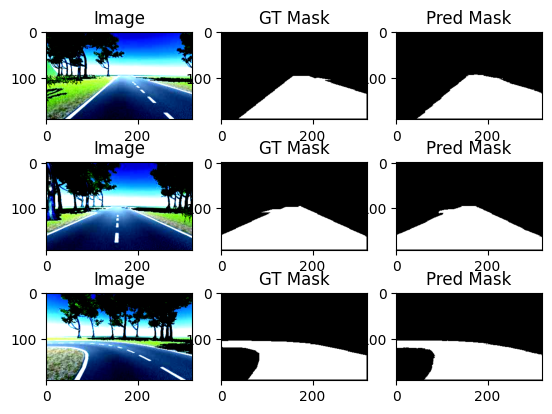

In [98]:
model2 = model2.to(device)
model2.eval()
with torch.no_grad():
    imgs, masks = next(iter(test_loader))
    imgs, masks = imgs.to(device), masks.to(device)
    imgs = imgs.float()
    outputs = torch.sigmoid(model2(imgs)).cpu()  # giữ float để hiển thị
    preds = (outputs > 0.01).int()              # threshold 0/1

import matplotlib.pyplot as plt

for i in range(3):  # hiển thị 3 ảnh
    plt.subplot(3,3,i*3+1)
    plt.imshow(imgs[i].permute(1,2,0).cpu())  # nếu đã ToTensor() thì không /255
    plt.title("Image")

    plt.subplot(3,3,i*3+2)
    plt.imshow(masks[i].squeeze().cpu(), cmap='gray')
    plt.title("GT Mask")

    plt.subplot(3,3,i*3+3)
    plt.imshow(preds[i,0], cmap ="gray")
    plt.title("Pred Mask")
plt.show()

In [ ]:
print(imgs[i].min().item(), imgs[i].max().item())

0.0 255.0


In [ ]:
!pip install thop ptflops fvcore


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61397 sha256=7eb4f362d0cbe1459ab1e9dc153e0f931de4fac98babd5ca03f7050f6d3904e3
  Stored in directory: /root/.cache/pip/wheels/ed/9f/a5/e4f5b27454ccd4596bd8b62432c7d6b1ca9fa22aef9d70a16a
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31527 sha256=025afb105417cbff64ec7f7569c67624dc5e005dad6a8debc026a27803790d63
  Stored in directory: /root/.cache/pip/wheels/7c/96/04/4f5f31ff812f684f69f40cb1634357812220aac58d4698048c
Successfully built fvcore iopath


In [ ]:
import torch
from thop import profile, clever_format
from torchvision import models

def value_model(model):
  model.to(device)
  model.eval()
  input = torch.randn(1, 3, 224, 224).to(device)
  macs, params = profile(model, inputs=(input,), verbose=False)
  # thop trả MACs (multiply-adds). Format it:
  macs, params = clever_format([macs, params], "%.3f")

  print(f"MACs (MADD): {macs}")
  print(f"Params: {params}")

In [ ]:
value_model(model2)

MACs (MADD): 322.196M
Params: 1.057M


In [ ]:
value_model(model3)

MACs (MADD): 698.511M
Params: 2.339M


In [ ]:
value_model(model4)

MACs (MADD): 4.873G
Params: 4.124M


In [ ]:
value_model(model)

Crop - Source shape: torch.Size([1, 128, 28, 28]), Target shape: torch.Size([1, 128, 28, 28])
Crop - Source shape: torch.Size([1, 64, 56, 56]), Target shape: torch.Size([1, 64, 56, 56])
Crop - Source shape: torch.Size([1, 32, 112, 112]), Target shape: torch.Size([1, 32, 112, 112])
Crop - Source shape: torch.Size([1, 16, 224, 224]), Target shape: torch.Size([1, 16, 224, 224])
MACs (MADD): 2.655G
Params: 1.944M


In [ ]:
value_model(model1)

Crop - Source shape: torch.Size([1, 64, 28, 28]), Target shape: torch.Size([1, 64, 28, 28])
Crop - Source shape: torch.Size([1, 32, 56, 56]), Target shape: torch.Size([1, 32, 56, 56])
Crop - Source shape: torch.Size([1, 16, 112, 112]), Target shape: torch.Size([1, 16, 112, 112])
Crop - Source shape: torch.Size([1, 8, 224, 224]), Target shape: torch.Size([1, 8, 224, 224])
MACs (MADD): 675.369M
Params: 487.289K


In [ ]:
value_model(PAM_model)

MACs (MADD): 337.594M
Params: 1.367M


/usr/local/lib/python3.12/dist-packages/thop/vision/calc_func.py:53: UserWarning: This API is being deprecated
  warnings.warn("This API is being deprecated")


In [ ]:
total_params = sum(p.numel() for p in model2.parameters())
trainable_params = sum(p.numel() for p in model2.parameters() if p.requires_grad)

print(f"Tổng số tham số: {total_params}")
print(f"Số tham số có thể train: {trainable_params}")



Tổng số tham số: 1056536
Số tham số có thể train: 1056536


In [ ]:
torch.save(model2.state_dict(), "/content/mobileNetV2_ver1.pth")


In [ ]:
!mkdir /content/drive/MyDrive/'Car racing  2025'/weight

In [ ]:
!cp -r /content/mobileNetV2_ver1.pth /content/drive/MyDrive/'Car racing  2025'/weight/mobileNetV2_ver1.pth

#TEST

In [121]:
test_image_path = "/content/data/test/images/raw_01266_png.rf.0f4eb27d88b58c053e0d57a58884012b.jpg"

In [122]:
test_image = cv2.imread(test_image_path)

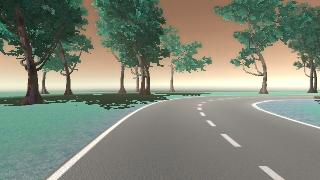

Image loaded and processed successfully.


In [123]:
from google.colab.patches import cv2_imshow

test_image = cv2.imread(test_image_path)

# Add a check to ensure the image was loaded successfully
if test_image is None:
    print(f"Error: Could not load image from {test_image_path}")
else:
    test_image = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB) #anh cv2 type
    cv2_imshow(test_image)
    test_image = val_transform(image=test_image)["image"]
    test_image = test_image.unsqueeze(0).to(device)
    print("Image loaded and processed successfully.")

In [124]:
test_output = torch.sigmoid(model2(test_image)).cpu()

In [125]:
pred_mask = test_output.squeeze().detach().numpy()


Text(0.5, 1.0, 'Pred Mask')

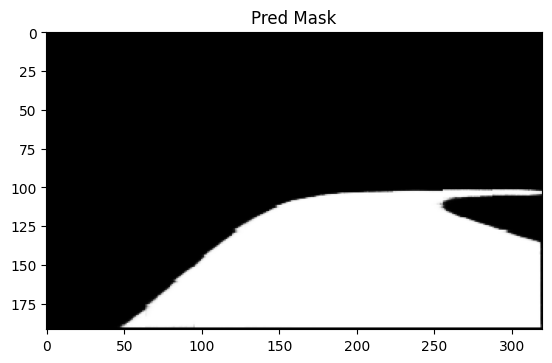

In [126]:
    plt.plot(3,3,1)
    plt.imshow(pred_mask, cmap ="gray")
    plt.title("Pred Mask")